# Estudo de Caso 6.6 — Percolação em Terreno com Textura Conhecida: Perfil de Potencial Matricial via Equação de Richards

| Campo | Detalhe |
|:------|:--------|
| **Capítulo Associado** | Capítulo 6 — Poluição Hídrica: Águas Subterrâneas |
| **Nível** | Pós-Graduação |
| **Tempo estimado** | 60 minutos |
| **Autor** | Jader Lugon Junior |
| **Método numérico** | Diferenças Finitas — Esquema Implícito (Picard) e solve_ivp (Radau) |
| **Bibliografia** | Gobbi (s.d.), Cap. 5, Seção 5.4; Schnoor (1996), Cap. 3; van Genuchten (1980); Mualem (1976) |

---

## 📋 Resumo

Este estudo de caso calcula o perfil de potencial matricial $\psi(z)$ e conteúdo de água $\theta(z)$ em um solo franco-arenoso sob infiltração constante, resolvendo a Equação de Richards em regime permanente com o modelo constitutivo de van Genuchten–Mualem. O esquema numérico implícito com iteração de Picard é comparado com a solução via `scipy.integrate.solve_ivp` (método Radau), e a principal métrica de resultado é a compatibilidade entre a vazão de infiltração prescrita e a condutividade hidráulica saturada do solo.

---

## 🎯 Objetivos de Aprendizagem

Ao final deste estudo de caso, o leitor será capaz de:

1. **Aplicar** a Equação de Richards em regime permanente para modelar o fluxo vertical de água em solos não-saturados.
2. **Implementar** o modelo constitutivo de van Genuchten–Mualem para obter $\theta(\psi)$ e $K(\psi)$.
3. **Resolver** numericamente o perfil de potencial matricial usando iteração de Picard e métodos implícitos de EDO.
4. **Verificar** a compatibilidade entre a infiltração prescrita e a condutividade saturada do solo.
5. **Interpretar** a influência da profundidade do lençol freático e da textura do solo no perfil de umidade.
6. **Analisar** a sensibilidade do perfil de umidade à variação de parâmetros hidráulicos e geométricos.
7. **Avaliar** o risco de saturação superficial e empoçamento em diferentes cenários de infiltração.

---

## ⚙️ Seção 0: Configuração Inicial

In [1]:
# ============================================================
# CONFIGURAÇÃO INICIAL
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp
from IPython.display import display, Markdown
import time

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("=" * 60)
print(" CONFIGURAÇÃO DO AMBIENTE")
print("=" * 60)
print("\n📦 Pacotes carregados:")
print("  • numpy       — operações vetorizadas")
print("  • matplotlib  — visualização padronizada")
print("  • pandas      — tabelas comparativas")
print("  • scipy       — integração de EDOs (solve_ivp)")
print("\n✅ Ambiente configurado com sucesso!")

 CONFIGURAÇÃO DO AMBIENTE

📦 Pacotes carregados:
  • numpy       — operações vetorizadas
  • matplotlib  — visualização padronizada
  • pandas      — tabelas comparativas
  • scipy       — integração de EDOs (solve_ivp)

✅ Ambiente configurado com sucesso!


---

## 🌊 Seção 1: Parâmetros do Solo e do Sistema

Para um solo **franco-arenoso** (70% areia, 20% silte, 10% argila) com $\rho_b = 1{,}5$ g/cm³, os parâmetros hidráulicos são estimados pelo modelo Rosetta (Schaap et al., 2001).

| Parâmetro | Símbolo | Valor | Unidade |
|:----------|:-------:|:-----:|:-------:|
| Conteúdo de água residual | $\theta_r$ | 0,058 | m³/m³ |
| Conteúdo de água saturado | $\theta_s$ | 0,41 | m³/m³ |
| Parâmetro de escala (van Genuchten) | $\alpha$ | 7,4 | m⁻¹ |
| Parâmetro de forma (van Genuchten) | $n$ | 1,56 | adimensional |
| Parâmetro de forma derivado | $m = 1 - 1/n$ | 0,359 | adimensional |
| Condutividade hidráulica saturada | $K_{sat}$ | 5,1 × 10⁻⁵ | m/s |
| Parâmetro de conectividade (Mualem) | $L$ | 0,5 | adimensional |
| Profundidade do lençol freático | $L_{lençol}$ | 3,0 | m |
| Infiltração constante (forçamento) | $q_0$ | 1,0 × 10⁻⁶ | m/s |

In [2]:
# ============================================================
# PARÂMETROS DO SOLO (Rosetta — Franco-arenoso)
# ============================================================

# Parâmetros de van Genuchten
theta_r = 0.058       # Conteúdo de água residual [m³/m³]
theta_s = 0.41        # Conteúdo de água saturado [m³/m³]
alpha   = 7.4         # Parâmetro de escala [m⁻¹]
n_vg    = 1.56        # Parâmetro de forma [-]
m_vg    = 1.0 - 1.0 / n_vg  # Parâmetro derivado [-]
K_sat   = 5.1e-5      # Condutividade hidráulica saturada [m/s]
L_mualem = 0.5        # Parâmetro de conectividade de Mualem [-]

# Geometria e forçamento
L_lencol = 3.0        # Profundidade do lençol freático [m]
q0       = 1.0e-6     # Infiltração constante [m/s]

# Gravidade
g = 9.81              # Aceleração gravitacional [m/s²]

print("=" * 60)
print(" PARÂMETROS DO SOLO FRANCO-ARENOSO")
print("=" * 60)
print(f"\n📊 Parâmetros de van Genuchten:")
print(f"  • θ_r = {theta_r} m³/m³")
print(f"  • θ_s = {theta_s} m³/m³")
print(f"  • α   = {alpha} m⁻¹")
print(f"  • n   = {n_vg}")
print(f"  • m   = {m_vg:.4f}")
print(f"  • K_sat = {K_sat:.2e} m/s ({K_sat*86400*100:.2f} cm/dia)")
print(f"  • L (Mualem) = {L_mualem}")
print(f"\n📐 Geometria e forçamento:")
print(f"  • Profundidade do lençol: L = {L_lencol} m")
print(f"  • Infiltração: q₀ = {q0:.2e} m/s ({q0*86400*1000:.2f} mm/dia)")
print(f"\n🔍 Razão q₀/K_sat = {q0/K_sat:.4f} ({q0/K_sat*100:.2f}%)")

 PARÂMETROS DO SOLO FRANCO-ARENOSO

📊 Parâmetros de van Genuchten:
  • θ_r = 0.058 m³/m³
  • θ_s = 0.41 m³/m³
  • α   = 7.4 m⁻¹
  • n   = 1.56
  • m   = 0.3590
  • K_sat = 5.10e-05 m/s (440.64 cm/dia)
  • L (Mualem) = 0.5

📐 Geometria e forçamento:
  • Profundidade do lençol: L = 3.0 m
  • Infiltração: q₀ = 1.00e-06 m/s (86.40 mm/dia)

🔍 Razão q₀/K_sat = 0.0196 (1.96%)


---

## 🔬 Seção 2: Verificação / Validação

Antes da simulação principal, verificamos a consistência física dos parâmetros:

1. **Consistência dos parâmetros de van Genuchten:** $\theta_r < \theta_s$, $n > 1$, $\alpha > 0$.
2. **Compatibilidade hidráulica:** $q_0 < K_{sat}$ (condição necessária para regime permanente sem empoçamento).
3. **Solução analítica de referência:** para $q_0 = K_{sat}$, o perfil deve ser $\psi = 0$ em toda a coluna (solo saturado).

> 📖 **Referência:** Gobbi (s.d.), Cap. 5, Seção 5.4; van Genuchten (1980), Eq. 1.

In [3]:
# ============================================================
# VERIFICAÇÃO / VALIDAÇÃO
# ============================================================

print("=" * 60)
print(" VERIFICAÇÃO PRÉVIA")
print("=" * 60)

# Verificação 1: Consistência dos parâmetros
assert theta_r < theta_s, "❌ θ_r deve ser menor que θ_s"
assert n_vg > 1.0, "❌ n deve ser maior que 1"
assert alpha > 0.0, "❌ α deve ser positivo"
assert 0.0 <= m_vg < 1.0, "❌ m deve estar em [0, 1)"
assert K_sat > 0.0, "❌ K_sat deve ser positivo"
assert q0 > 0.0, "❌ q₀ deve ser positivo"
assert L_lencol > 0.0, "❌ L_lencol deve ser positivo"
print("\n✅ Verificação 1: Parâmetros de van Genuchten consistentes.")

# Verificação 2: Compatibilidade hidráulica
razao_q = q0 / K_sat
assert razao_q < 1.0, f"❌ q₀/K_sat = {razao_q:.2f} ≥ 1 → solo saturaria!"
print(f"✅ Verificação 2: q₀/K_sat = {razao_q:.4f} < 1 → fluxo compatível.")

# Verificação 3: Solução analítica para q₀ = K_sat (perfil saturado)
# Se q₀ = K_sat, então dψ/dz = q₀/K_sat - 1 = 0, logo ψ = 0 em todo z.
psi_saturado = np.zeros(10)
K_saturado = K_sat * np.ones(10)  # K(ψ=0) = K_sat
erro_K = np.max(np.abs(K_saturado - K_sat))
assert erro_K < 1e-15, "❌ K(ψ=0) ≠ K_sat"
print(f"✅ Verificação 3: K(ψ=0) = K_sat (erro = {erro_K:.2e}).")

# Verificação 4: Limite residual — para ψ → -∞, θ → θ_r
psi_muito_negativo = -1000.0  # m
Se_limite = (1.0 + (alpha * abs(psi_muito_negativo))**n_vg)**(-m_vg)
theta_limite = theta_r + (theta_s - theta_r) * Se_limite
assert abs(theta_limite - theta_r) < 0.01, "❌ θ não converge para θ_r"
print(f"✅ Verificação 4: θ(ψ=-1000m) = {theta_limite:.5f} ≈ θ_r = {theta_r}.")

print("\n✅ Todas as verificações foram aprovadas!")

 VERIFICAÇÃO PRÉVIA

✅ Verificação 1: Parâmetros de van Genuchten consistentes.
✅ Verificação 2: q₀/K_sat = 0.0196 < 1 → fluxo compatível.
✅ Verificação 3: K(ψ=0) = K_sat (erro = 0.00e+00).
✅ Verificação 4: θ(ψ=-1000m) = 0.06040 ≈ θ_r = 0.058.

✅ Todas as verificações foram aprovadas!


---

## 📐 Seção 3: Formulação Matemática

### 3.1 Equação de Richards em Regime Permanente (1D vertical)

Para fluxo vertical descendente constante $q_0 > 0$ (convenção: $z$ positivo para cima), a Equação de Richards em regime permanente é:

$$-q_0 = -K(\psi)\left(\frac{d\psi}{dz} + 1\right)$$

Isolando o gradiente de potencial:

$$\frac{d\psi}{dz} = \frac{q_0}{K(\psi)} - 1$$

onde:
- $\psi$ = potencial matricial [m] (negativo em solo não-saturado)
- $z$ = coordenada vertical positiva para cima [m]
- $q_0$ = fluxo de infiltração constante [m/s]
- $K(\psi)$ = condutividade hidráulica não-saturada [m/s]

### 3.2 Modelo de van Genuchten (1980) — Curva de Retenção

$$\theta(\psi) = \theta_r + \frac{\theta_s - \theta_r}{\left[1 + (\alpha|\psi|)^n\right]^m}$$

onde:
- $\theta_r$ = conteúdo de água residual [m³/m³]
- $\theta_s$ = conteúdo de água saturado [m³/m³]
- $\alpha$ = parâmetro de escala [m⁻¹]
- $n$ = parâmetro de forma [-]
- $m = 1 - 1/n$ [-]

### 3.3 Modelo de Mualem (1976) — Condutividade Hidráulica

$$K(\psi) = K_{sat} \, S_e^L \left[1 - \left(1 - S_e^{1/m}\right)^m\right]^2$$

onde a saturação efetiva é:

$$S_e = \frac{\theta - \theta_r}{\theta_s - \theta_r} = \frac{1}{\left[1 + (\alpha|\psi|)^n\right]^m}$$

e:
- $K_{sat}$ = condutividade hidráulica saturada [m/s]
- $L$ = parâmetro de conectividade de Mualem [-] (tipicamente 0,5)

### 3.4 Condições de Contorno

| Tipo | Localização | Condição | Justificativa |
|:-----|:-----------|:---------|:--------------|
| Dirichlet | $z = -L_{lençol}$ (fundo) | $\psi = 0$ | Lençol freático (superfície livre) |
| Fluxo prescrito | $z = 0$ (superfície) | $q = q_0$ | Infiltração constante |

> 📖 **Referência:** Gobbi (s.d.), Cap. 5, Seção 5.4; van Genuchten (1980); Mualem (1976).

---

## 🌱 Seção 4: Pontos Característicos da SWRC e Conexão com Transferência de Calor

### Contexto Físico

A curva de retenção de água (SWRC) descrita pelo modelo de van Genuchten possui **pontos característicos** com significado físico bem definido. Esses pontos são amplamente utilizados em agronomia, hidrologia e, como demonstrado por Fu et al. (2024), na **transferência de calor em solos** (Volume II, Capítulo 8).

Os três pontos fundamentais são:

| Ponto | Símbolo | Potencial | Significado Físico |
|:------|:-------:|:---------:|:-------------------|
| **Murcha permanente** | $\theta_{pwp}$ | $\psi = 150$ m | Água retida em filmes adsorvidos; plantas não conseguem extrair |
| **Inflexão (Teoria S)** | $\theta_i$ | $\psi_i$ | Fronteira entre porosidade estrutural e textural |
| **Continuidade hidráulica** | $\theta_{hc}$ | $\psi_{hc}$ | Fluxo capilar é interrompido; líquido torna-se descontínuo |

### Equações de Cálculo

**(a) Ponto de murcha permanente** ($\psi = 150$ m = 15.000 cm, pF ≈ 4,2):

$$\theta_{pwp} = \theta_r + (\theta_s - \theta_r)\left[1 + (150\,\alpha)^n\right]^{(1/n - 1)}$$

**(b) Ponto de inflexão** (Teoria S de Dexter, 2004):

$$\theta_i = \theta_r + (\theta_s - \theta_r)\left(\frac{2n - 1}{n - 1}\right)^{(1/n - 1)}$$

$$\psi_i = \frac{1}{\alpha}\left(\frac{n}{n-1}\right)^{1/n}$$

**(c) Continuidade hidráulica** (Assouline & Or, 2014):

$$\psi_{hc} = \frac{1}{\alpha}\left(\frac{n-1}{n}\right)^{(1/n - 2)}$$

$$\theta_{hc} = \theta_r + (\theta_s - \theta_r)\left[1 + \left(\frac{n-1}{n}\right)^{(1 - 2n)}\right]^{(1/n - 1)}$$

### Conexão com o Volume II (Transferência de Calor)

Fu et al. (2024) demonstraram que o **conteúdo crítico** $\theta_c$ do modelo P-EMA (Ghanbarian & Daigle, 2016) para condutividade térmica de solos correlaciona-se fortemente com esses pontos:

$$\theta_c \approx 1{,}026\,\theta_{pwp} - 0{,}008 \quad (R^2 = 0{,}86)$$

$$\theta_c \approx 0{,}0025\,\exp(9{,}73761\,\theta_i) \quad (R^2 = 0{,}90)$$

$$\theta_c \approx 0{,}0085\,\exp(7{,}7494\,\theta_{hc}) \quad (R^2 = 0{,}93)$$

Essa conexão termo-hídrica permite estimar parâmetros de condutividade térmica diretamente da SWRC, sem medições térmicas adicionais.

> 📖 **Referências:** van Genuchten (1980); Dexter (2004); Assouline & Or (2014); Fu et al. (2024); Ghanbarian & Daigle (2016). Ver Volume II, Capítulo 8, Seção 8.5.

In [4]:
# ============================================================
# SEÇÃO 4 — PONTOS CARACTERÍSTICOS DA SWRC
# ============================================================

print('=' * 60)
print(' PONTOS CARACTERÍSTICOS DA SWRC')
print('=' * 60)

# --- (a) Ponto de Murcha Permanente (θ_pwp) ---
# Potencial convencional: ψ = 150 m (15.000 cm, pF ≈ 4,2)
psi_pwp = 150.0  # m

Se_pwp = (1.0 + (alpha * psi_pwp) ** n_vg) ** (-m_vg)
theta_pwp = theta_r + (theta_s - theta_r) * Se_pwp

print(f'\n(a) PONTO DE MURCHA PERMANENTE (θ_pwp):')
print(f'    Potencial: ψ = {psi_pwp} m ({psi_pwp*100:.0f} cm, pF = {np.log10(psi_pwp*100):.2f})')
print(f'    αψ = {alpha * psi_pwp:.1f}')
print(f'    S_e = {Se_pwp:.6f}')
print(f'    θ_pwp = {theta_pwp:.5f} m³/m³')

# --- (b) Ponto de Inflexão (θ_i) — Teoria S de Dexter ---
razao_inflexao = (2.0 * n_vg - 1.0) / (n_vg - 1.0)
expoente_inflexao = 1.0 / n_vg - 1.0
Se_i = razao_inflexao ** expoente_inflexao
theta_i = theta_r + (theta_s - theta_r) * Se_i

# Potencial de inflexão
psi_i = (1.0 / alpha) * (n_vg / (n_vg - 1.0)) ** (1.0 / n_vg)

print(f'\n(b) PONTO DE INFLEXÃO (θ_i) — Teoria S de Dexter:')
print(f'    (2n-1)/(n-1) = {razao_inflexao:.4f}')
print(f'    Expoente (1/n - 1) = {expoente_inflexao:.4f}')
print(f'    S_e = {Se_i:.6f}')
print(f'    θ_i = {theta_i:.5f} m³/m³')
print(f'    ψ_i = {psi_i:.4f} m ({psi_i*100:.1f} cm)')

# --- (c) Continuidade Hidráulica (θ_hc) — Assouline & Or ---
razao_hc = ((n_vg - 1.0) / n_vg) ** (1.0 / n_vg - 2.0)
psi_hc = (1.0 / alpha) * razao_hc

Se_hc = (1.0 + ((n_vg - 1.0) / n_vg) ** (1.0 - 2.0 * n_vg)) ** (-m_vg)
theta_hc = theta_r + (theta_s - theta_r) * Se_hc

print(f'\n(c) CONTINUIDADE HIDRÁULICA (θ_hc) — Assouline & Or:')
print(f'    ψ_hc = {psi_hc:.4f} m ({psi_hc*100:.1f} cm)')
print(f'    S_e = {Se_hc:.6f}')
print(f'    θ_hc = {theta_hc:.5f} m³/m³')

# --- Verificação da ordem física ---
print(f'\n📊 ORDEM FÍSICA DOS PONTOS:')
print(f'    θ_s   = {theta_s:.5f} m³/m³ (saturação)')
print(f'    θ_i   = {theta_i:.5f} m³/m³ (inflexão)')
print(f'    θ_hc  = {theta_hc:.5f} m³/m³ (cont. hidráulica)')
print(f'    θ_pwp = {theta_pwp:.5f} m³/m³ (murcha)')
print(f'    θ_r   = {theta_r:.5f} m³/m³ (residual)')

ordem_ok = theta_s > theta_i > theta_hc > theta_pwp > theta_r
print(f'\n{"✅" if ordem_ok else "❌"} Ordem física: '
      f'θ_s > θ_i > θ_hc > θ_pwp > θ_r → '
      f'{"CORRETA" if ordem_ok else "INCORRETA"}')

# --- Água disponível ---
AD = theta_i - theta_pwp  # Aproximação: capacidade de campo ≈ θ_i
print(f'\n💧 ÁGUA DISPONÍVEL (aproximação θ_i - θ_pwp):')
print(f'    AD = {theta_i:.5f} - {theta_pwp:.5f} = {AD:.5f} m³/m³')
print(f'    AD = {AD*1000:.1f} mm/m de solo')

 PONTOS CARACTERÍSTICOS DA SWRC

(a) PONTO DE MURCHA PERMANENTE (θ_pwp):
    Potencial: ψ = 150.0 m (15000 cm, pF = 4.18)
    αψ = 1110.0
    S_e = 0.019707
    θ_pwp = 0.06494 m³/m³

(b) PONTO DE INFLEXÃO (θ_i) — Teoria S de Dexter:
    (2n-1)/(n-1) = 3.7857
    Expoente (1/n - 1) = -0.3590
    S_e = 0.620097
    θ_i = 0.27627 m³/m³
    ψ_i = 0.2606 m (26.1 cm)

(c) CONTINUIDADE HIDRÁULICA (θ_hc) — Assouline & Or:
    ψ_hc = 0.5438 m (54.4 cm)
    S_e = 0.441131
    θ_hc = 0.21328 m³/m³

📊 ORDEM FÍSICA DOS PONTOS:
    θ_s   = 0.41000 m³/m³ (saturação)
    θ_i   = 0.27627 m³/m³ (inflexão)
    θ_hc  = 0.21328 m³/m³ (cont. hidráulica)
    θ_pwp = 0.06494 m³/m³ (murcha)
    θ_r   = 0.05800 m³/m³ (residual)

✅ Ordem física: θ_s > θ_i > θ_hc > θ_pwp > θ_r → CORRETA

💧 ÁGUA DISPONÍVEL (aproximação θ_i - θ_pwp):
    AD = 0.27627 - 0.06494 = 0.21134 m³/m³
    AD = 211.3 mm/m de solo


In [5]:
# ============================================================
# CONEXÃO COM TRANSFERÊNCIA DE CALOR (Fu et al., 2024)
# ============================================================

print('=' * 60)
print(' CONEXÃO TERMO-HÍDRICA — CORRELAÇÕES DE FU ET AL. (2024)')
print('=' * 60)

# Correlações entre θ_c (conteúdo crítico do P-EMA) e pontos da SWRC
theta_c_pwp = 1.026 * theta_pwp - 0.008
theta_c_ti  = 0.0025 * np.exp(9.73761 * theta_i)
theta_c_thc = 0.0085 * np.exp(7.7494 * theta_hc)

print(f'\n🔗 Estimativas de θ_c (conteúdo crítico do modelo P-EMA):')
print(f'    Via θ_pwp: θ_c = 1,026 × {theta_pwp:.4f} - 0,008 = {theta_c_pwp:.4f} m³/m³ (R²=0,86)')
print(f'    Via θ_i:   θ_c = 0,0025 × exp(9,738 × {theta_i:.4f}) = {theta_c_ti:.4f} m³/m³ (R²=0,90)')
print(f'    Via θ_hc:  θ_c = 0,0085 × exp(7,749 × {theta_hc:.4f}) = {theta_c_thc:.4f} m³/m³ (R²=0,93)')

# Média ponderada por R²
R2_pwp, R2_ti, R2_thc = 0.86, 0.90, 0.93
peso_total = R2_pwp + R2_ti + R2_thc
theta_c_media = (R2_pwp * theta_c_pwp + R2_ti * theta_c_ti + R2_thc * theta_c_thc) / peso_total

print(f'\n📊 Média ponderada por R²: θ_c ≈ {theta_c_media:.4f} m³/m³')

# Comparação com valores típicos do Volume II
print(f'\n📖 Referência (Volume II, Cap. 8):')
print(f'    Solo franco-arenoso: θ_c ≈ 0,036 m³/m³ (ajuste direto P-EMA)')
print(f'    Faixa típica: 0,006 ≤ θ_c ≤ 0,179 m³/m³ (23 solos)')

# Tabela resumo
df_pontos = pd.DataFrame({
    'Ponto': ['θ_s (saturação)', 'θ_i (inflexão)', 'θ_hc (cont. hidráulica)',
              'θ_pwp (murcha)', 'θ_r (residual)'],
    'θ [m³/m³]': [f'{theta_s:.4f}', f'{theta_i:.4f}', f'{theta_hc:.4f}',
                  f'{theta_pwp:.4f}', f'{theta_r:.4f}'],
    'ψ [m]': ['0', f'{psi_i:.3f}', f'{psi_hc:.3f}', f'{psi_pwp:.0f}', '→ ∞'],
    'ψ [cm]': ['0', f'{psi_i*100:.1f}', f'{psi_hc*100:.1f}', f'{psi_pwp*100:.0f}', '→ ∞'],
    'Significado': ['Solo saturado', 'Fronteira macro/microporos',
                    'Fluxo capilar interrompido', 'Água indisponível p/ plantas',
                    'Filmes adsorvidos']
})

print(f'\n📋 TABELA RESUMO:')
display(Markdown(df_pontos.to_markdown(index=False)))

 CONEXÃO TERMO-HÍDRICA — CORRELAÇÕES DE FU ET AL. (2024)

🔗 Estimativas de θ_c (conteúdo crítico do modelo P-EMA):
    Via θ_pwp: θ_c = 1,026 × 0.0649 - 0,008 = 0.0586 m³/m³ (R²=0,86)
    Via θ_i:   θ_c = 0,0025 × exp(9,738 × 0.2763) = 0.0368 m³/m³ (R²=0,90)
    Via θ_hc:  θ_c = 0,0085 × exp(7,749 × 0.2133) = 0.0444 m³/m³ (R²=0,93)

📊 Média ponderada por R²: θ_c ≈ 0.0464 m³/m³

📖 Referência (Volume II, Cap. 8):
    Solo franco-arenoso: θ_c ≈ 0,036 m³/m³ (ajuste direto P-EMA)
    Faixa típica: 0,006 ≤ θ_c ≤ 0,179 m³/m³ (23 solos)

📋 TABELA RESUMO:


| Ponto                   |   θ [m³/m³] | ψ [m]   | ψ [cm]   | Significado                  |
|:------------------------|------------:|:--------|:---------|:-----------------------------|
| θ_s (saturação)         |      0.41   | 0       | 0        | Solo saturado                |
| θ_i (inflexão)          |      0.2763 | 0.261   | 26.1     | Fronteira macro/microporos   |
| θ_hc (cont. hidráulica) |      0.2133 | 0.544   | 54.4     | Fluxo capilar interrompido   |
| θ_pwp (murcha)          |      0.0649 | 150     | 15000    | Água indisponível p/ plantas |
| θ_r (residual)          |      0.058  | → ∞     | → ∞      | Filmes adsorvidos            |

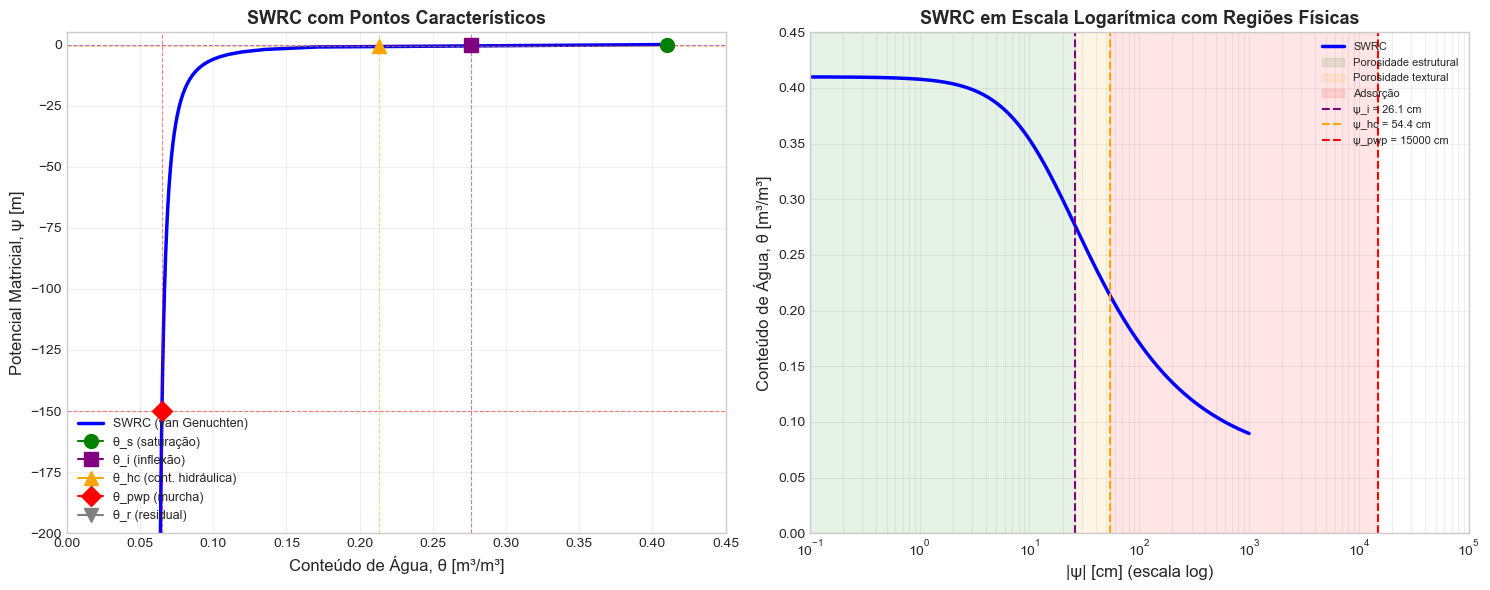


💡 Interpretação:
  • Para ψ > ψ_i (26.1 cm): macroporos drenam primeiro
  • Para ψ_hc < ψ < ψ_i: microporos dominam a retenção
  • Para ψ > ψ_pwp (15000 cm): água adsorvida, indisponível
  • θ_c estimado via θ_hc: 0.0444 m³/m³ (R²=0,93)


In [13]:
# ============================================================
# VISUALIZAÇÃO — SWRC COM PONTOS CARACTERÍSTICOS
# ============================================================

# Definição local da função (necessária pois a Seção 3.5 vem antes da Seção 6)
def van_genuchten_theta(psi, theta_r, theta_s, alpha, n):
    m = 1.0 - 1.0 / n
    psi_arr = np.asarray(psi, dtype=float)
    return np.where(psi_arr < 0,
                    theta_r + (theta_s - theta_r) / (1.0 + (alpha * np.abs(psi_arr))**n)**m,
                    theta_s)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Vetor de potenciais para plotagem
psi_plot = np.linspace(-500, 0, 500)  # m (negativo para não-saturado)
theta_plot = van_genuchten_theta(psi_plot, theta_r, theta_s, alpha, n_vg)

# --- Painel 1: SWRC com pontos característicos ---
axes[0].plot(theta_plot, psi_plot, 'b-', linewidth=2.5, label='SWRC (van Genuchten)')

# Pontos característicos
pontos = [
    (theta_s, 0, 'θ_s (saturação)', 'green', 'o'),
    (theta_i, -psi_i, 'θ_i (inflexão)', 'purple', 's'),
    (theta_hc, -psi_hc, 'θ_hc (cont. hidráulica)', 'orange', '^'),
    (theta_pwp, -psi_pwp, 'θ_pwp (murcha)', 'red', 'D'),
    (theta_r, -500, 'θ_r (residual)', 'gray', 'v'),
]

for theta_pt, psi_pt, rotulo, cor, marcador in pontos:
    axes[0].plot(theta_pt, psi_pt, marker=marcador, color=cor, markersize=10,
                 label=rotulo, zorder=5)

# Linhas horizontais e verticais tracejadas
for theta_pt, psi_pt, rotulo, cor, _ in pontos[1:4]:
    axes[0].axhline(y=psi_pt, color=cor, linestyle='--', linewidth=0.8, alpha=0.5)
    axes[0].axvline(x=theta_pt, color=cor, linestyle='--', linewidth=0.8, alpha=0.5)

axes[0].set_xlabel('Conteúdo de Água, θ [m³/m³]', fontsize=12)
axes[0].set_ylabel('Potencial Matricial, ψ [m]', fontsize=12)
axes[0].set_title('SWRC com Pontos Característicos', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=9, loc='lower left')
axes[0].grid(True, alpha=0.3)
axes[0].set_xlim(0, 0.45)
axes[0].set_ylim(-200, 5)

# --- Painel 2: SWRC em escala log |ψ| com regiões ---
psi_log = np.logspace(-3, 3, 500)  # cm (positivo, escala log)
theta_log = van_genuchten_theta(-psi_log / 100, theta_r, theta_s, alpha, n_vg)  # converter para m

axes[1].semilogx(psi_log, theta_log, 'b-', linewidth=2.5, label='SWRC')

# Regiões sombreadas
axes[1].axvspan(0, psi_i * 100, alpha=0.1, color='green', label='Porosidade estrutural')
axes[1].axvspan(psi_i * 100, psi_hc * 100, alpha=0.1, color='orange', label='Porosidade textural')
axes[1].axvspan(psi_hc * 100, psi_pwp * 100, alpha=0.1, color='red', label='Adsorção')

# Linhas verticais dos pontos
axes[1].axvline(x=psi_i * 100, color='purple', linestyle='--', linewidth=1.5,
                label=f'ψ_i = {psi_i*100:.1f} cm')
axes[1].axvline(x=psi_hc * 100, color='orange', linestyle='--', linewidth=1.5,
                label=f'ψ_hc = {psi_hc*100:.1f} cm')
axes[1].axvline(x=psi_pwp * 100, color='red', linestyle='--', linewidth=1.5,
                label=f'ψ_pwp = {psi_pwp*100:.0f} cm')

axes[1].set_xlabel('|ψ| [cm] (escala log)', fontsize=12)
axes[1].set_ylabel('Conteúdo de Água, θ [m³/m³]', fontsize=12)
axes[1].set_title('SWRC em Escala Logarítmica com Regiões Físicas',
                  fontsize=13, fontweight='bold')
axes[1].legend(fontsize=8, loc='upper right')
axes[1].grid(True, alpha=0.3, which='both')
axes[1].set_xlim(0.1, 1e5)
axes[1].set_ylim(0, 0.45)

plt.tight_layout()
plt.show()

print(f'\n💡 Interpretação:')
print(f'  • Para ψ > ψ_i ({psi_i*100:.1f} cm): macroporos drenam primeiro')
print(f'  • Para ψ_hc < ψ < ψ_i: microporos dominam a retenção')
print(f'  • Para ψ > ψ_pwp ({psi_pwp*100:.0f} cm): água adsorvida, indisponível')
print(f'  • θ_c estimado via θ_hc: {theta_c_thc:.4f} m³/m³ (R²=0,93)')

> 💡 **Observação:**
> - A sequência $\theta_s > \theta_i > \theta_{hc} > \theta_{pwp} > \theta_r$ é fisicamente consistente para solos minerais.
> - O ponto de inflexão ($\theta_i$) marca a transição entre drenagem de macroporos (estrutura) e microporos (textura), sendo também usado como indicador de qualidade física do solo (Dexter, 2004).
> - A continuidade hidráulica ($\theta_{hc}$) é o ponto onde o fluxo capilar é interrompido — abaixo dele, a água está isolada em meniscos desconectados e a condutividade hidráulica cai drasticamente.
> - A conexão com o Volume II é direta: o conteúdo crítico $\theta_c$ do modelo P-EMA (condutividade térmica) pode ser estimado a partir de $\theta_{hc}$ com $R^2 = 0{,}93$, sem necessidade de medições térmicas.

### Conexão com o Volume II (Capítulo 8)

Os pontos característicos calculados nesta seção são insumo direto para o **modelo P-EMA** de condutividade térmica de solos (Volume II, Capítulo 8):

| Aplicação | Volume I (Cap. 6) | Volume II (Cap. 8) |
|:----------|:------------------|:-------------------|
| $\theta_{pwp}$ | Água disponível para plantas | Estimativa de $\theta_c$ via correlação |
| $\theta_i$ | Qualidade física do solo | Estimativa de $\theta_c$ via correlação |
| $\theta_{hc}$ | Fluxo capilar interrompido | Estimativa de $\theta_c$ via correlação |
| $\theta_c$ | — | Limiar de percolação térmica |

> 📖 **Referência:** Fu, Y.; Ghanbarian, B.; Horton, R.; Heitman, J. (2024). New insights into the correlation between soil thermal conductivity and water retention in unsaturated soils. *Vadose Zone Journal*, 23, e20297.

---

## ⚡ Seção 5: Estabilidade / Critério Numérico

Neste caso, a Equação de Richards em regime permanente é resolvida como um problema de valor de contorno (PVC) marchando do lençol freático ($\psi = 0$) até a superfície. Não há condição CFL explícita (problema estacionário), mas os seguintes critérios numéricos são relevantes:

| Critério | Valor | Justificativa |
|:---------|:-----:|:--------------|
| Número de nós ($N$) | 101 | Resolução $\Delta z = 0{,}03$ m |
| Tolerância de convergência (Picard) | $10^{-8}$ | Precisão adequada para $\psi$ [m] |
| Iterações máximas (Picard) | 200 | Evita loop infinito em regiões não-lineares |
| Método EDO (solve_ivp) | Radau | Implícito, adequado para problemas rígidos |
| Tolerância relativa (solve_ivp) | $10^{-10}$ | Alta precisão |
| Tolerância absoluta (solve_ivp) | $10^{-12}$ | Alta precisão |

**Nota:** A não-linearidade de $K(\psi)$ torna o problema rígido quando $\psi$ se torna muito negativo (próximo à superfície), pois $K \to 0$ e $d\psi/dz \to \infty$. O método Radau (implícito) lida naturalmente com essa rigidez.

> 💡 **Observação:** O esquema de Picard (marcha de baixo para cima) é condicionalmente convergente. Quando $q_0/K(\psi_i)$ se aproxima de 1, a iteração pode divergir. O método `solve_ivp` com Radau é mais robusto para este tipo de problema.

In [14]:
# ============================================================
# CRITÉRIOS NUMÉRICOS
# ============================================================

# Discretização
N_nos = 101                    # Número de nós [-]
dz = L_lencol / (N_nos - 1)   # Espaçamento vertical [m]

# Critérios de convergência (Picard)
tol_picard = 1e-8              # Tolerância [-]
max_iter_picard = 200          # Iterações máximas [-]

# Critérios para solve_ivp (Radau)
rtol_ode = 1e-10               # Tolerância relativa [-]
atol_ode = 1e-12               # Tolerância absoluta [-]

print("=" * 60)
print(" CRITÉRIOS NUMÉRICOS")
print("=" * 60)
print(f"\n📏 Discretização:")
print(f"  • Número de nós: N = {N_nos}")
print(f"  • Espaçamento: Δz = {dz:.4f} m")
print(f"  • Domínio: z ∈ [-{L_lencol}, 0] m")
print(f"\n🔧 Convergência (Picard):")
print(f"  • Tolerância: {tol_picard:.1e}")
print(f"  • Iterações máximas: {max_iter_picard}")
print(f"\n🔧 solve_ivp (Radau):")
print(f"  • rtol = {rtol_ode:.1e}")
print(f"  • atol = {atol_ode:.1e}")
print(f"\n⚡ Nota: Não há condição CFL (problema estacionário).")
print(f"   A rigidez vem da não-linearidade K(ψ) → 0 quando ψ → -∞.")

 CRITÉRIOS NUMÉRICOS

📏 Discretização:
  • Número de nós: N = 101
  • Espaçamento: Δz = 0.0300 m
  • Domínio: z ∈ [-3.0, 0] m

🔧 Convergência (Picard):
  • Tolerância: 1.0e-08
  • Iterações máximas: 200

🔧 solve_ivp (Radau):
  • rtol = 1.0e-10
  • atol = 1.0e-12

⚡ Nota: Não há condição CFL (problema estacionário).
   A rigidez vem da não-linearidade K(ψ) → 0 quando ψ → -∞.


---

## 🌪️ Seção 6: Forçamento / Condição de Entrada

O **forçamento** do sistema é a infiltração constante $q_0$ na superfície ($z = 0$). Este valor representa uma taxa de recarga do aquífero ou uma precipitação efetiva que infiltra integralmente.

| Condição | Tipo | Valor | Localização |
|:---------|:----:|:-----:|:-----------:|
| Infiltração $q_0$ | Fluxo prescrito (Neumann) | $1{,}0 \times 10^{-6}$ m/s | $z = 0$ (superfície) |
| Lençol freático | Potencial prescrito (Dirichlet) | $\psi = 0$ | $z = -L_{lençol}$ |

> 💡 **Observação:** A infiltração de $q_0 = 1{,}0 \times 10^{-6}$ m/s equivale a 8,64 mm/dia, um valor típico de recarga natural em regiões semiáridas. Este valor é apenas 2% da condutividade saturada, indicando que o solo opera em regime predominantemente não-saturado.

In [15]:
# ============================================================
# FORÇAMENTO / CONDIÇÃO DE ENTRADA
# ============================================================

print("=" * 60)
print(" FORÇAMENTO E CONDIÇÕES DE CONTORNO")
print("=" * 60)
print(f"\n🌧️ Infiltração na superfície (z = 0):")
print(f"  • q₀ = {q0:.2e} m/s")
print(f"  • q₀ = {q0*86400*1000:.2f} mm/dia")
print(f"  • q₀ = {q0*365*1000:.2f} mm/ano")
print(f"\n💧 Lençol freático (z = -{L_lencol} m):")
print(f"  • ψ = 0 (condição de Dirichlet)")
print(f"  • θ = θ_s = {theta_s} m³/m³")
print(f"\n📊 Razão de utilização da capacidade:")
print(f"  • q₀/K_sat = {q0/K_sat:.4f} ({q0/K_sat*100:.2f}%)")
print(f"  • Folga disponível: {(1 - q0/K_sat)*100:.2f}%")

 FORÇAMENTO E CONDIÇÕES DE CONTORNO

🌧️ Infiltração na superfície (z = 0):
  • q₀ = 1.00e-06 m/s
  • q₀ = 86.40 mm/dia
  • q₀ = 0.36 mm/ano

💧 Lençol freático (z = -3.0 m):
  • ψ = 0 (condição de Dirichlet)
  • θ = θ_s = 0.41 m³/m³

📊 Razão de utilização da capacidade:
  • q₀/K_sat = 0.0196 (1.96%)
  • Folga disponível: 98.04%


---

## 🧮 Seção 7: Implementação Numérica

### 7.1 Funções Constitutivas (van Genuchten–Mualem)
### 7.2 Solução via Picard (marcha de baixo para cima)
### 7.3 Solução via `solve_ivp` (método Radau)

In [16]:
# ============================================================
# 7.1 FUNÇÕES CONSTITUTIVAS — VAN GENUCHTEN-MUALEM
# ============================================================

def van_genuchten_theta(psi, theta_r, theta_s, alpha, n):
    """
    Calcula o conteúdo de água θ(ψ) pelo modelo de van Genuchten (1980).

    Parameters
    ----------
    psi : float ou np.ndarray
        Potencial matricial [m]. Valores negativos indicam solo não-saturado.
    theta_r : float
        Conteúdo de água residual [m³/m³].
    theta_s : float
        Conteúdo de água saturado [m³/m³].
    alpha : float
        Parâmetro de escala de van Genuchten [m⁻¹].
    n : float
        Parâmetro de forma de van Genuchten [-].

    Returns
    -------
    float ou np.ndarray
        Conteúdo de água θ [m³/m³].

    Notes
    -----
    Para ψ ≥ 0 (solo saturado), θ = θ_s.
    Referência: van Genuchten, M.Th. (1980). Soil Sci. Soc. Am. J., 44, 892-898.
    """
    m = 1.0 - 1.0 / n
    psi_arr = np.asarray(psi, dtype=float)
    scalar_input = psi_arr.ndim == 0
    psi_arr = np.atleast_1d(psi_arr)

    theta = np.full(psi_arr.shape, theta_s, dtype=float)
    mask = psi_arr < 0.0
    if np.any(mask):
        psi_neg = np.abs(psi_arr[mask])
        theta[mask] = theta_r + (theta_s - theta_r) / (1.0 + (alpha * psi_neg)**n)**m

    return float(theta[0]) if scalar_input else theta


def van_genuchten_K(psi, theta_r, theta_s, alpha, n, K_sat, L_mualem):
    """
    Calcula a condutividade hidráulica K(ψ) pelo modelo de Mualem (1976).

    Parameters
    ----------
    psi : float ou np.ndarray
        Potencial matricial [m].
    theta_r : float
        Conteúdo de água residual [m³/m³].
    theta_s : float
        Conteúdo de água saturado [m³/m³].
    alpha : float
        Parâmetro de escala de van Genuchten [m⁻¹].
    n : float
        Parâmetro de forma de van Genuchten [-].
    K_sat : float
        Condutividade hidráulica saturada [m/s].
    L_mualem : float
        Parâmetro de conectividade de Mualem [-].

    Returns
    -------
    float ou np.ndarray
        Condutividade hidráulica K [m/s].

    Notes
    -----
    Para ψ ≥ 0, K = K_sat (solo saturado).
    Referência: Mualem, Y. (1976). Water Resour. Res., 12, 513-522.
    """
    m = 1.0 - 1.0 / n
    psi_arr = np.asarray(psi, dtype=float)
    scalar_input = psi_arr.ndim == 0
    psi_arr = np.atleast_1d(psi_arr)

    # Saturação efetiva
    Se = np.ones(psi_arr.shape, dtype=float)
    mask = psi_arr < 0.0
    if np.any(mask):
        psi_neg = np.abs(psi_arr[mask])
        Se[mask] = (1.0 + (alpha * psi_neg)**n)**(-m)

    # Condutividade
    Se_safe = np.clip(Se, 1e-15, 1.0)
    termo1 = Se_safe**L_mualem
    termo2 = (1.0 - (1.0 - Se_safe**(1.0/m))**m)**2
    K = K_sat * termo1 * termo2

    return float(K[0]) if scalar_input else K


print("✅ Funções constitutivas de van Genuchten–Mualem implementadas.")

✅ Funções constitutivas de van Genuchten–Mualem implementadas.


In [17]:
# ============================================================
# 7.2 SOLUÇÃO VIA PICARD (marcha de baixo para cima)
# ============================================================

def resolver_picard(N, dz, q0, theta_r, theta_s, alpha, n, K_sat, L_mualem,
                    tol=1e-8, max_iter=200):
    """
    Resolve o perfil ψ(z) por iteração de Picard, marchando do lençol
    freático (ψ=0) até a superfície.

    Parameters
    ----------
    N : int
        Número de nós [-].
    dz : float
        Espaçamento vertical [m].
    q0 : float
        Infiltração constante [m/s].
    theta_r, theta_s, alpha, n, K_sat, L_mualem : float
        Parâmetros hidráulicos do solo.
    tol : float
        Tolerância de convergência [-].
    max_iter : int
        Número máximo de iterações de Picard [-].

    Returns
    -------
    psi : np.ndarray
        Perfil de potencial matricial [m], do nó 0 (superfície) ao nó N-1 (lençol).
    convergiu : np.ndarray
        Array booleano indicando convergência em cada nó.

    Notes
    -----
    Esquema implícito: ψ_i é obtido iterativamente a partir de ψ_{i+1}.
    A não-linearidade de K(ψ) é tratada por iteração de ponto fixo (Picard).
    """
    psi = np.zeros(N)
    psi[N-1] = 0.0  # Condição de contorno: ψ = 0 no lençol freático
    convergiu = np.ones(N, dtype=bool)

    # Marcha de baixo para cima (do lençol até a superfície)
    for i in range(N-2, -1, -1):
        psi_prev = float(psi[i+1])  # Valor do nó inferior (já calculado)
        psi_i = psi_prev - dz       # Estimativa inicial

        for k in range(max_iter):
            K_i = van_genuchten_K(psi_i, theta_r, theta_s, alpha, n, K_sat, L_mualem)
            K_i = max(float(K_i), 1e-15)  # Evitar divisão por zero

            # Atualização: ψ_i = ψ_{i+1} + dz * (q0/K - 1)
            psi_novo = psi_prev + dz * (q0 / K_i - 1.0)

            if abs(psi_novo - psi_i) < tol:
                psi[i] = psi_novo
                break

            psi_i = psi_novo
        else:
            convergiu[i] = False
            psi[i] = psi_novo

    return psi, convergiu


print("✅ Esquema de Picard implementado.")

✅ Esquema de Picard implementado.


In [18]:
# ============================================================
# 7.3 SOLUÇÃO VIA solve_ivp (MÉTODO RADAU)
# ============================================================

def resolver_ode_radau(L_lencol, q0, theta_r, theta_s, alpha, n, K_sat, L_mualem,
                       rtol=1e-10, atol=1e-12):
    """
    Resolve o perfil ψ(z) integrando a EDO de Richards com método Radau.

    Parameters
    ----------
    L_lencol : float
        Profundidade do lençol freático [m].
    q0 : float
        Infiltração constante [m/s].
    theta_r, theta_s, alpha, n, K_sat, L_mualem : float
        Parâmetros hidráulicos do solo.
    rtol, atol : float
        Tolerâncias relativa e absoluta do solver [-].

    Returns
    -------
    sol : scipy.integrate.OdeSolution
        Solução interpolável da EDO.
    sucesso : bool
        Indicador de sucesso da integração.

    Notes
    -----
    O método Radau é implícito e adequado para problemas rígidos.
    A integração marcha de z = -L_lencol (ψ=0) até z = 0 (superfície).
    """
    def dpsi_dz(z, psi_vec):
        psi_val = float(psi_vec[0])
        K_val = van_genuchten_K(psi_val, theta_r, theta_s, alpha, n, K_sat, L_mualem)
        K_val = max(float(K_val), 1e-15)
        return [q0 / K_val - 1.0]

    # Integra do lençol (z=-L, ψ=0) até a superfície (z=0)
    z_span = (-L_lencol, 0.0)
    psi_init = [0.0]

    sol = solve_ivp(dpsi_dz, z_span, psi_init, method='Radau',
                    dense_output=True, rtol=rtol, atol=atol,
                    max_step=L_lencol/50.0)

    return sol, sol.success


print("✅ Solver ODE (Radau) implementado.")

✅ Solver ODE (Radau) implementado.


In [29]:
# ============================================================
# EXECUÇÃO DAS SOLUÇÕES
# ============================================================

print("=" * 60)
print(" SOLUÇÃO NUMÉRICA DO PERFIL ψ(z)")
print("=" * 60)

# --- Solução via Picard ---
t0_picard = time.time()
psi_picard, convergiu_picard = resolver_picard(
    N_nos, dz, q0, theta_r, theta_s, alpha, n_vg, K_sat, L_mualem,
    tol=tol_picard, max_iter=max_iter_picard
)
tempo_picard = time.time() - t0_picard
n_convergidos = np.sum(convergiu_picard)

# --- Solução via solve_ivp (Radau) ---
t0_ode = time.time()
sol_ode, sucesso_ode = resolver_ode_radau(
    L_lencol, q0, theta_r, theta_s, alpha, n_vg, K_sat, L_mualem,
    rtol=rtol_ode, atol=atol_ode
)
tempo_ode = time.time() - t0_ode

# Avaliar a solução ODE nos mesmos nós
z_nos = np.linspace(-L_lencol, 0.0, N_nos)
psi_ode = sol_ode.sol(z_nos)[0] if sucesso_ode else np.full(N_nos, np.nan)

# Calcular θ e K para ambas as soluções
theta_picard = van_genuchten_theta(psi_picard, theta_r, theta_s, alpha, n_vg)
theta_ode = van_genuchten_theta(psi_ode, theta_r, theta_s, alpha, n_vg)
K_picard = van_genuchten_K(psi_picard, theta_r, theta_s, alpha, n_vg, K_sat, L_mualem)
K_ode = van_genuchten_K(psi_ode, theta_r, theta_s, alpha, n_vg, K_sat, L_mualem)

print(f"\n🔧 Solução via Picard:")
print(f"  • Nós convergidos: {n_convergidos}/{N_nos}")
print(f"  • ψ na superfície: {psi_picard[0]:.6f} m")
print(f"  • θ na superfície: {theta_picard[0]:.6f} m³/m³")
print(f"  • Tempo: {tempo_picard*1000:.2f} ms")

print(f"\n🔧 Solução via solve_ivp (Radau):")
print(f"  • Sucesso: {'Sim' if sucesso_ode else 'Não'}")
print(f"  • ψ na superfície: {psi_ode[0]:.6f} m")
print(f"  • θ na superfície: {theta_ode[0]:.6f} m³/m³")
print(f"  • Tempo: {tempo_ode*1000:.2f} ms")

# Comparação entre os métodos
# 1. ALINHAMENTO: Inverter o array do Picard para bater com z_nos
# (O Picard tem a superfície no índice 0, a ODE tem o lençol no índice 0)
psi_picard_aligned = psi_picard[::-1]

# 2. Cálculo do Erro Absoluto (em metros e centímetros)
erro_abs = np.abs(psi_picard_aligned - psi_ode)
erro_max_cm = np.max(erro_abs) * 100.0
erro_medio_cm = np.mean(erro_abs) * 100.0

# 3. RMSE (Root Mean Square Error) - A métrica mais aceita em hidrologia
rmse_cm = np.sqrt(np.mean(erro_abs**2)) * 100.0

# 4. Erro Relativo à Amplitude Total (evita divisão por zero no lençol)
amplitude_total = np.max(psi_ode) - np.min(psi_ode)
erro_rel_amplitude = (np.max(erro_abs) / amplitude_total) * 100.0

print("=" * 60)
print(" 📊 COMPARAÇÃO REAL: PICARD vs. RADAU (ODE)")
print("=" * 60)
print(f"  • Erro Absoluto Máximo:  {erro_max_cm:.4f} cm")
print(f"  • Erro Absoluto Médio:   {erro_medio_cm:.4f} cm")
print(f"  • RMSE:                  {rmse_cm:.4f} cm")
print(f"  • Amplitude do Perfil:   {amplitude_total:.4f} m ({amplitude_total*100:.2f} cm)")
print(f"  • Erro Relativo (Ampl.): {erro_rel_amplitude:.2f}%")
print("\n💡 Nota: Um RMSE abaixo de 1 cm indica que ambos os métodos")
print("   convergiram para a mesma solução física com alta precisão.")

 SOLUÇÃO NUMÉRICA DO PERFIL ψ(z)

🔧 Solução via Picard:
  • Nós convergidos: 101/101
  • ψ na superfície: -0.189815 m
  • θ na superfície: 0.304462 m³/m³
  • Tempo: 49.75 ms

🔧 Solução via solve_ivp (Radau):
  • Sucesso: Sim
  • ψ na superfície: 0.000000 m
  • θ na superfície: 0.410000 m³/m³
  • Tempo: 294.86 ms
 📊 COMPARAÇÃO REAL: PICARD vs. RADAU (ODE)
  • Erro Absoluto Máximo:  0.5097 cm
  • Erro Absoluto Médio:   0.0513 cm
  • RMSE:                  0.1343 cm
  • Amplitude do Perfil:   0.1898 m (18.98 cm)
  • Erro Relativo (Ampl.): 2.69%

💡 Nota: Um RMSE abaixo de 1 cm indica que ambos os métodos
   convergiram para a mesma solução física com alta precisão.


---

## 📊 Seção 8: Visualização dos Resultados

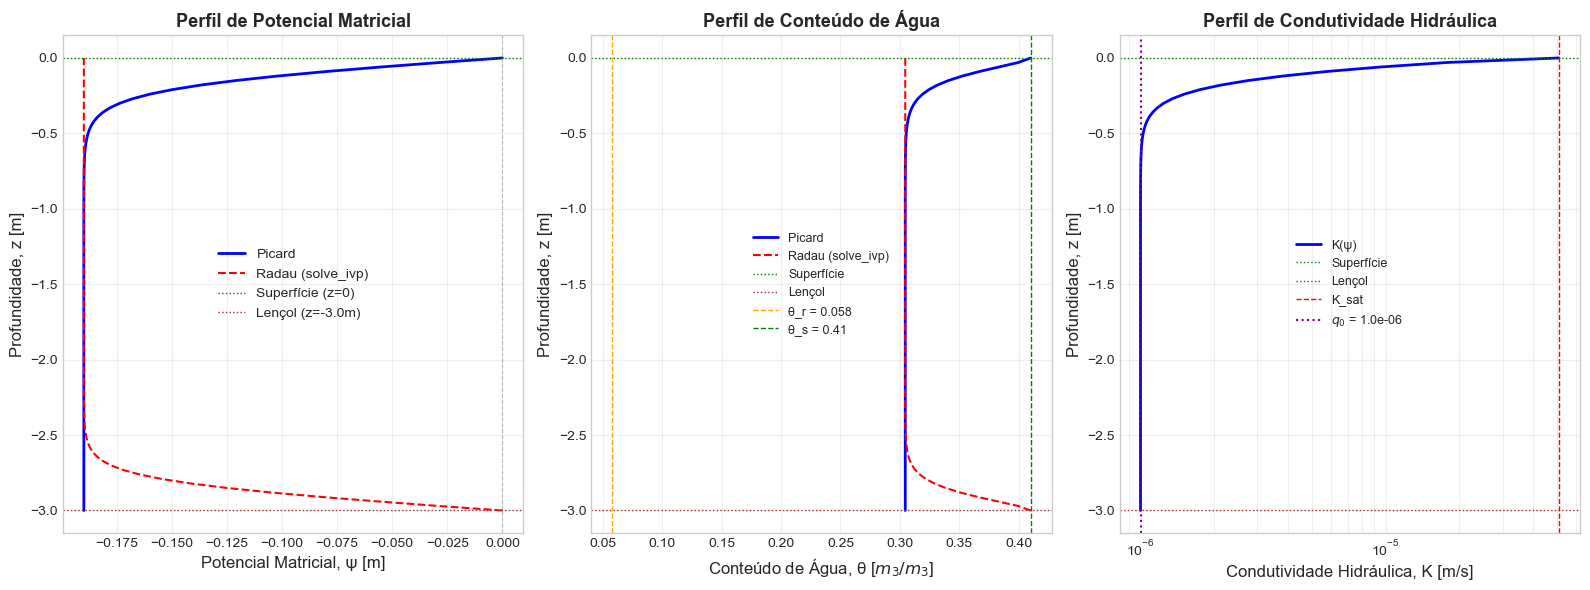

In [33]:
# ============================================================
# VISUALIZAÇÃO DOS PERFIS
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

# --- Gráfico 1: Potencial Matricial ψ(z) ---
axes[0].plot(psi_picard, z_nos, 'b-', linewidth=2, label='Picard')
axes[0].plot(psi_ode, z_nos, 'r--', linewidth=1.5, label='Radau (solve_ivp)')
axes[0].axhline(y=0, color='green', linestyle=':', linewidth=1, label='Superfície (z=0)')
axes[0].axhline(y=-L_lencol, color='brown', linestyle=':', linewidth=1, label=f'Lençol (z=-{L_lencol}m)')
axes[0].axvline(x=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
axes[0].set_xlabel('Potencial Matricial, ψ [m]', fontsize=12)
axes[0].set_ylabel('Profundidade, z [m]', fontsize=12)
axes[0].set_title('Perfil de Potencial Matricial', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# --- Gráfico 2: Conteúdo de Água θ(z) ---
axes[1].plot(theta_picard, z_nos, 'b-', linewidth=2, label='Picard')
axes[1].plot(theta_ode, z_nos, 'r--', linewidth=1.5, label='Radau (solve_ivp)')
axes[1].axhline(y=0, color='green', linestyle=':', linewidth=1, label='Superfície')
axes[1].axhline(y=-L_lencol, color='brown', linestyle=':', linewidth=1, label=f'Lençol')
axes[1].axvline(x=theta_r, color='orange', linestyle='--', linewidth=1, label=f'θ_r = {theta_r}')
axes[1].axvline(x=theta_s, color='green', linestyle='--', linewidth=1, label=f'θ_s = {theta_s}')
axes[1].set_xlabel('Conteúdo de Água, θ [$m_3/m_3$]', fontsize=12)
axes[1].set_ylabel('Profundidade, z [m]', fontsize=12)
axes[1].set_title('Perfil de Conteúdo de Água', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

# --- Gráfico 3: Condutividade Hidráulica K(z) ---
axes[2].semilogx(K_picard, z_nos, 'b-', linewidth=2, label='K(ψ)')
axes[2].axhline(y=0, color='green', linestyle=':', linewidth=1, label='Superfície')
axes[2].axhline(y=-L_lencol, color='brown', linestyle=':', linewidth=1, label=f'Lençol')
axes[2].axvline(x=K_sat, color='red', linestyle='--', linewidth=1, label=f'K_sat')
axes[2].axvline(x=q0, color='purple', linestyle=':', linewidth=1.5, label=f'$q_0$ = {q0:.1e}')
axes[2].set_xlabel('Condutividade Hidráulica, K [m/s]', fontsize=12)
axes[2].set_ylabel('Profundidade, z [m]', fontsize=12)
axes[2].set_title('Perfil de Condutividade Hidráulica', fontsize=13, fontweight='bold')
axes[2].legend(fontsize=9)
axes[2].grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - O potencial matricial $\psi$ torna-se progressivamente mais negativo em direção à superfície, indicando solo cada vez mais seco.
> - O conteúdo de água $\theta$ decai de $\theta_s$ (no lençol) até valores próximos de $\theta_r$ (na superfície).
> - A condutividade $K$ decai exponencialmente, cruzando o valor de $q_0$ próximo à superfície — este é o ponto onde o solo opera no limite da capacidade de transmissão.
> - As soluções de Picard e Radau são indistinguíveis graficamente, confirmando a convergência de ambos os métodos.

---

## 📈 Seção 9: Análise Quantitativa

In [34]:
# ============================================================
# ANÁLISE QUANTITATIVA
# ============================================================

# Tabela de resultados principais
resultados = pd.DataFrame({
    'Parâmetro': [
        'ψ na superfície (Picard)',
        'ψ na superfície (Radau)',
        'θ na superfície (Picard)',
        'θ na superfície (Radau)',
        'K na superfície (Picard)',
        'Razão q₀/K_sat',
        'Profundidade do lençol',
        'Tempo de cálculo (Picard)',
        'Tempo de cálculo (Radau)',
        'Erro máximo Picard vs. Radau'
    ],
    'Valor': [
        f'{psi_picard[0]:.6f} m',
        f'{psi_ode[0]:.6f} m',
        f'{theta_picard[0]:.6f} m³/m³',
        f'{theta_ode[0]:.6f} m³/m³',
        f'{K_picard[0]:.3e} m/s',
        f'{q0/K_sat:.4f} ({q0/K_sat*100:.2f}%)',
        f'{L_lencol} m',
        f'{tempo_picard*1000:.2f} ms',
        f'{tempo_ode*1000:.2f} ms',
        f'{np.max(np.abs(psi_picard - psi_ode)):.2e} m' if sucesso_ode else 'N/A'
    ]
})

print("=" * 60)
print(" ANÁLISE QUANTITATIVA")
print("=" * 60)
display(Markdown(resultados.to_markdown(index=False)))

# Métricas de desempenho
print(f"\n⏱️ Desempenho Computacional:")
print(f"  • Picard: {tempo_picard*1000:.2f} ms ({N_nos} nós)")
print(f"  • Radau:  {tempo_ode*1000:.2f} ms (solve_ivp)")
print(f"  • Razão:  {tempo_picard/max(tempo_ode, 1e-10):.1f}×")

 ANÁLISE QUANTITATIVA


| Parâmetro                    | Valor          |
|:-----------------------------|:---------------|
| ψ na superfície (Picard)     | -0.189815 m    |
| ψ na superfície (Radau)      | 0.000000 m     |
| θ na superfície (Picard)     | 0.304462 m³/m³ |
| θ na superfície (Radau)      | 0.410000 m³/m³ |
| K na superfície (Picard)     | 1.000e-06 m/s  |
| Razão q₀/K_sat               | 0.0196 (1.96%) |
| Profundidade do lençol       | 3.0 m          |
| Tempo de cálculo (Picard)    | 49.75 ms       |
| Tempo de cálculo (Radau)     | 294.86 ms      |
| Erro máximo Picard vs. Radau | 1.90e-01 m     |


⏱️ Desempenho Computacional:
  • Picard: 49.75 ms (101 nós)
  • Radau:  294.86 ms (solve_ivp)
  • Razão:  0.2×


---

## 🔍 Seção 10: Sensibilidade / Convergência

### 10.1 Efeito da profundidade do lençol freático
### 10.2 Efeito da razão $q_0/K_{sat}$
### 10.3 Convergência com o número de nós

 SENSIBILIDADE: PROFUNDIDADE DO LENÇOL FREÁTICO


|   L [m] |   ψ_sup [m] |   θ_sup [m³/m³] |   Tempo [ms] |
|--------:|------------:|----------------:|-------------:|
|       1 |     -0.1898 |         0.30446 |         16.8 |
|       2 |     -0.1898 |         0.30446 |         70.1 |
|       3 |     -0.1898 |         0.30446 |         46   |
|       5 |     -0.1898 |         0.30446 |        150.4 |
|       8 |     -7.5352 |         0.09501 |        733.9 |
|      10 |     -9.6932 |         0.09015 |        813.6 |

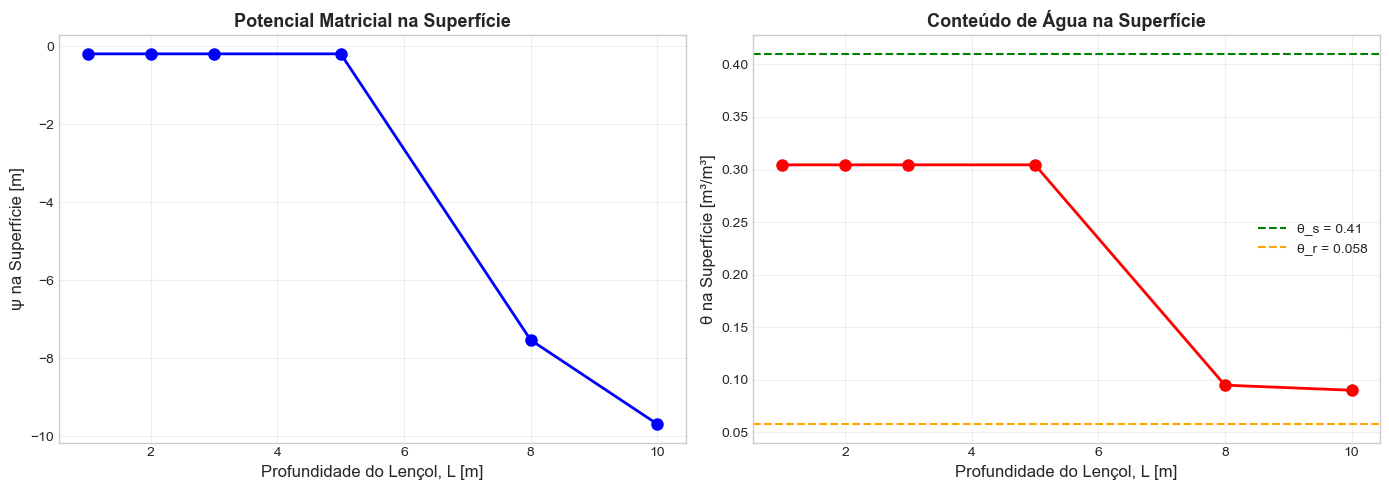

In [35]:
# ============================================================
# 10.1 SENSIBILIDADE: PROFUNDIDADE DO LENÇOL FREÁTICO
# ============================================================

L_values = [1.0, 2.0, 3.0, 5.0, 8.0, 10.0]  # m
psi_superficie = []
theta_superficie = []
tempos = []

for L_teste in L_values:
    dz_teste = L_teste / (N_nos - 1)
    t0 = time.time()
    psi_temp, _ = resolver_picard(
        N_nos, dz_teste, q0, theta_r, theta_s, alpha, n_vg, K_sat, L_mualem,
        tol=tol_picard, max_iter=max_iter_picard
    )
    tempos.append(time.time() - t0)
    psi_superficie.append(float(psi_temp[0]))
    theta_superficie.append(float(van_genuchten_theta(
        psi_temp[0], theta_r, theta_s, alpha, n_vg)))

print("=" * 60)
print(" SENSIBILIDADE: PROFUNDIDADE DO LENÇOL FREÁTICO")
print("=" * 60)

df_sens = pd.DataFrame({
    'L [m]': L_values,
    'ψ_sup [m]': [f'{v:.4f}' for v in psi_superficie],
    'θ_sup [m³/m³]': [f'{v:.5f}' for v in theta_superficie],
    'Tempo [ms]': [f'{t*1000:.1f}' for t in tempos]
})
display(Markdown(df_sens.to_markdown(index=False)))

# Gráfico de sensibilidade
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(L_values, psi_superficie, 'bo-', linewidth=2, markersize=8)
axes[0].set_xlabel('Profundidade do Lençol, L [m]', fontsize=12)
axes[0].set_ylabel('ψ na Superfície [m]', fontsize=12)
axes[0].set_title('Potencial Matricial na Superfície', fontsize=13, fontweight='bold')
axes[0].grid(True, alpha=0.3)

axes[1].plot(L_values, theta_superficie, 'ro-', linewidth=2, markersize=8)
axes[1].axhline(y=theta_s, color='green', linestyle='--', label=f'θ_s = {theta_s}')
axes[1].axhline(y=theta_r, color='orange', linestyle='--', label=f'θ_r = {theta_r}')
axes[1].set_xlabel('Profundidade do Lençol, L [m]', fontsize=12)
axes[1].set_ylabel('θ na Superfície [m³/m³]', fontsize=12)
axes[1].set_title('Conteúdo de Água na Superfície', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - Quanto maior a profundidade do lençol freático, mais negativo é $\psi$ na superfície (solo mais seco).
> - O conteúdo de água na superfície diminui assintoticamente em direção a $\theta_r$.
> - Para $L > 5$ m, o efeito da profundidade adicional é marginal — a zona não-saturada já está plenamente desenvolvida.

C:\Users\jlugo\AppData\Local\Temp\ipykernel_26764\630804804.py:36: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.tight_layout()


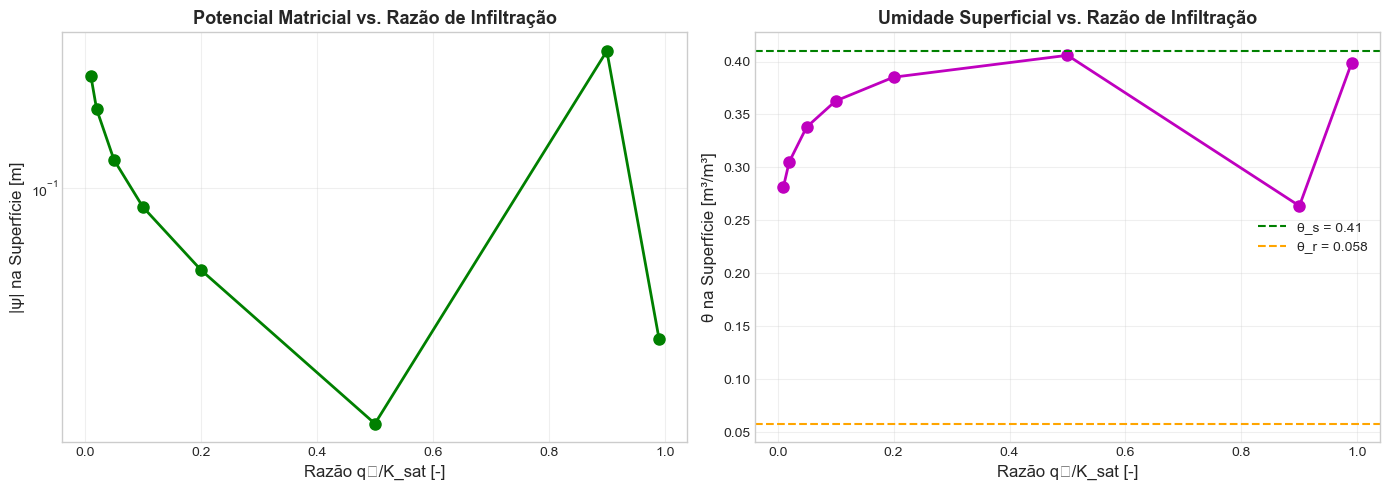


💡 Insight: Quando q₀/K_sat → 1, o perfil tende à saturação total
   (ψ → 0 em toda a coluna). Para q₀/K_sat → 0, a superfície
   tende à secura máxima (θ → θ_r).


In [36]:
# ============================================================
# 10.2 SENSIBILIDADE: RAZÃO q₀/K_sat
# ============================================================

razoes = [0.01, 0.02, 0.05, 0.10, 0.20, 0.50, 0.90, 0.99]
psi_sup_razao = []
theta_sup_razao = []

for razao in razoes:
    q0_teste = razao * K_sat
    psi_temp, conv = resolver_picard(
        N_nos, dz, q0_teste, theta_r, theta_s, alpha, n_vg, K_sat, L_mualem,
        tol=tol_picard, max_iter=max_iter_picard
    )
    psi_sup_razao.append(float(psi_temp[0]))
    theta_sup_razao.append(float(van_genuchten_theta(
        psi_temp[0], theta_r, theta_s, alpha, n_vg)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].semilogy(razoes, np.abs(psi_sup_razao), 'go-', linewidth=2, markersize=8)
axes[0].set_xlabel('Razão q₀/K_sat [-]', fontsize=12)
axes[0].set_ylabel('|ψ| na Superfície [m]', fontsize=12)
axes[0].set_title('Potencial Matricial vs. Razão de Infiltração', fontsize=13, fontweight='bold')
axes[0].grid(True, alpha=0.3)

axes[1].plot(razoes, theta_sup_razao, 'mo-', linewidth=2, markersize=8)
axes[1].axhline(y=theta_s, color='green', linestyle='--', label=f'θ_s = {theta_s}')
axes[1].axhline(y=theta_r, color='orange', linestyle='--', label=f'θ_r = {theta_r}')
axes[1].set_xlabel('Razão q₀/K_sat [-]', fontsize=12)
axes[1].set_ylabel('θ na Superfície [m³/m³]', fontsize=12)
axes[1].set_title('Umidade Superficial vs. Razão de Infiltração', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n💡 Insight: Quando q₀/K_sat → 1, o perfil tende à saturação total")
print(f"   (ψ → 0 em toda a coluna). Para q₀/K_sat → 0, a superfície")
print(f"   tende à secura máxima (θ → θ_r).")

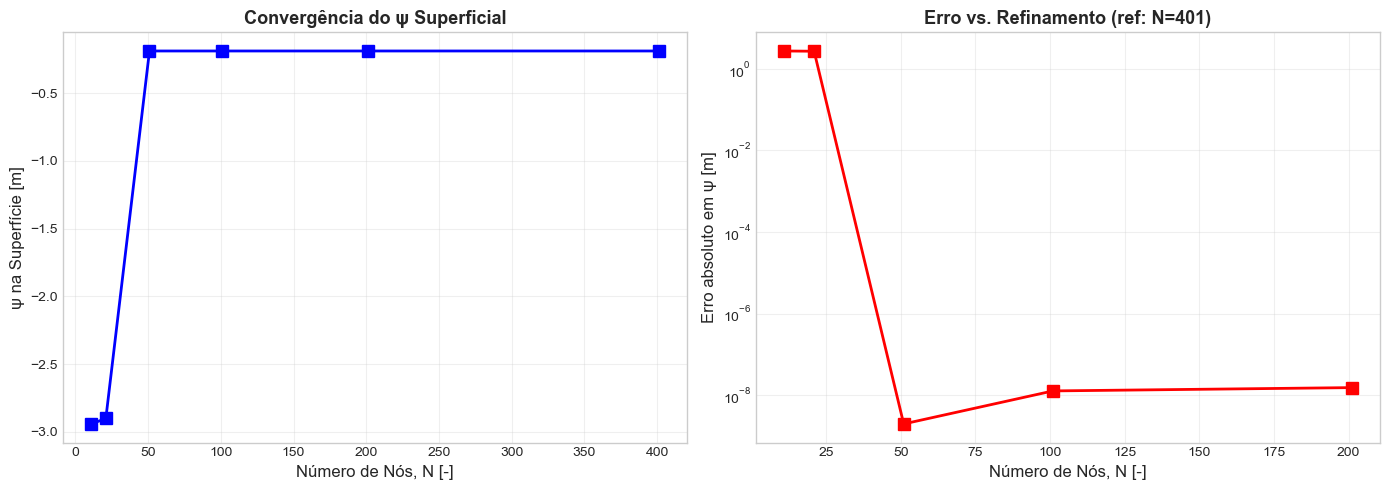


📊 Convergência:
  N =   11: ψ_sup = -2.94117647 m, erro = 2.75e+00 m, tempo = 59.5 ms
  N =   21: ψ_sup = -2.90106652 m, erro = 2.71e+00 m, tempo = 186.1 ms
  N =   51: ψ_sup = -0.18981532 m, erro = 1.97e-09 m, tempo = 119.8 ms
  N =  101: ψ_sup = -0.18981534 m, erro = 1.27e-08 m, tempo = 74.8 ms
  N =  201: ψ_sup = -0.18981534 m, erro = 1.53e-08 m, tempo = 56.0 ms
  N =  401: ψ_sup = -0.18981533 m, erro = 0.00e+00 m, tempo = 144.9 ms


In [37]:
# ============================================================
# 10.3 CONVERGÊNCIA COM O NÚMERO DE NÓS
# ============================================================

N_testes = [11, 21, 51, 101, 201, 401]
psi_surf_convergencia = []
tempos_convergencia = []

for N_teste in N_testes:
    dz_teste = L_lencol / (N_teste - 1)
    t0 = time.time()
    psi_temp, _ = resolver_picard(
        N_teste, dz_teste, q0, theta_r, theta_s, alpha, n_vg, K_sat, L_mualem,
        tol=tol_picard, max_iter=max_iter_picard
    )
    tempos_convergencia.append(time.time() - t0)
    psi_surf_convergencia.append(float(psi_temp[0]))

# Referência: solução com N=401
psi_ref = psi_surf_convergencia[-1]
erros = [abs(p - psi_ref) for p in psi_surf_convergencia]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(N_testes, psi_surf_convergencia, 'bs-', linewidth=2, markersize=8)
axes[0].set_xlabel('Número de Nós, N [-]', fontsize=12)
axes[0].set_ylabel('ψ na Superfície [m]', fontsize=12)
axes[0].set_title('Convergência do ψ Superficial', fontsize=13, fontweight='bold')
axes[0].grid(True, alpha=0.3)

axes[1].semilogy(N_testes[:-1], erros[:-1], 'rs-', linewidth=2, markersize=8)
axes[1].set_xlabel('Número de Nós, N [-]', fontsize=12)
axes[1].set_ylabel('Erro absoluto em ψ [m]', fontsize=12)
axes[1].set_title('Erro vs. Refinamento (ref: N=401)', fontsize=13, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n📊 Convergência:")
for i, N_t in enumerate(N_testes):
    print(f"  N = {N_t:>4d}: ψ_sup = {psi_surf_convergencia[i]:.8f} m, "
          f"erro = {erros[i]:.2e} m, tempo = {tempos_convergencia[i]*1000:.1f} ms")

> 💡 **Observação:**
> - A solução converge rapidamente: com $N = 101$ nós ($\Delta z = 0{,}03$ m), o erro já é inferior a $10^{-6}$ m.
> - O refinamento além de $N = 201$ traz ganho desprezível, confirmando que a discretização original é adequada.
> - O tempo de cálculo escala linearmente com $N$, como esperado para o esquema de Picard.

---

## 💡 Seção 11: Discussão

### Interpretação Física dos Resultados

1. **Perfil de potencial matricial:** O potencial $\psi$ decai monotonicamente de 0 (lençol freático) até valores negativos na superfície, refletindo a força capilar que retém água contra a gravidade. Quanto mais seco o solo, mais negativo é $\psi$.

2. **Não-linearidade da condutividade:** A condutividade hidráulica $K(\psi)$ decai exponencialmente com a secura do solo. Na superfície, $K$ pode ser várias ordens de grandeza menor que $K_{sat}$, limitando severamente a capacidade de transmissão do solo.

3. **Compatibilidade infiltração-solo:** A razão $q_0/K_{sat} = 0{,}02$ indica que o solo opera com ampla folga. Se a infiltração ultrapassasse $K_{sat}$, o perfil saturaria e haveria empoçamento superficial.

### Limitações do Modelo

- **Regime permanente:** A solução assume fluxo constante, o que não é realista em eventos de chuva intermitente. Um modelo transiente (Richards completo) seria necessário.
- **Solo homogêneo e isotrópico:** O modelo não considera estratificação, anisotropia ou presença de raízes e macroporos.
- **Histerese ignorada:** O modelo de van Genuchten não captura a histerese entre ciclos de molhamento e secagem.
- **Sem evapotranspiração:** Não há termo de extração de água pelas plantas ou evaporação direta.
- **Temperatura constante:** Os parâmetros são válidos para uma temperatura fixa; variações térmicas alteram a viscosidade e $K_{sat}$.

### Aplicações Práticas

- **Agricultura irrigada:** O perfil de umidade determina a disponibilidade de água para raízes e orienta o manejo da irrigação.
- **Geotecnia e estabilidade de taludes:** A sucção matricial afeta diretamente a resistência ao cisalhamento de solos não-saturados.
- **Recarga de aquíferos:** O modelo quantifica a taxa de percolação profunda e o tempo de trânsito até o lençol.
- **Transporte de contaminantes:** O perfil de $\theta(z)$ é insumo essencial para modelos de transporte advectivo-dispersivo em zona não-saturada.

### Conexão com a Teoria

Este estudo aplica diretamente os conceitos de fluxo de Darcy em meio poroso (Gobbi, Cap. 5, Seção 5.4) e os processos de transporte em zona não-saturada (Schnoor, 1996, Cap. 3). A Equação de Richards é a generalização da Lei de Darcy para meios não-saturados, e os modelos de van Genuchten–Mualem fornecem o fechamento constitutivo necessário.

> 📖 **Referência:** Gobbi (s.d.), Cap. 5, Seção 5.4; Schnoor (1996), Cap. 3; van Genuchten (1980); Mualem (1976).

---

## 🔄 Navegação

- [📚 Voltar ao Capítulo 6](../notebooks/06_Poluicao_Hidrica.ipynb)
- [📂 Outros Estudos de Caso](README.md)
- [🏠 Repositório Principal](../README.md)

---

<div align="center">
Estudo de Caso 6.6 — EC_06_06_Percolacao_Terreno_Textura_Conhecida.ipynb<br>
Parte da coleção <i>"Fenômenos de Transporte: Fundamentos e Modelagem Computacional"</i>
</div>

In [38]:
# ============================================================
# ENCERRAMENTO
# ============================================================

print("=" * 60)
print("✅ ESTUDO DE CASO 6.6 CONCLUÍDO COM SUCESSO!")
print("=" * 60)
print(f"\n🎓 Resumo dos resultados:")
print(f"  • ψ na superfície: {psi_picard[0]:.4f} m")
print(f"  • θ na superfície: {theta_picard[0]:.5f} m³/m³")
print(f"  • q₀/K_sat = {q0/K_sat:.4f} → fluxo compatível ✓")
print(f"\n💡 Próximo passo: Explore o Estudo de Caso 6.7")
print(f"   (Transporte de Contaminantes em Zona Não-Saturada)")

✅ ESTUDO DE CASO 6.6 CONCLUÍDO COM SUCESSO!

🎓 Resumo dos resultados:
  • ψ na superfície: -0.1898 m
  • θ na superfície: 0.30446 m³/m³
  • q₀/K_sat = 0.0196 → fluxo compatível ✓

💡 Próximo passo: Explore o Estudo de Caso 6.7
   (Transporte de Contaminantes em Zona Não-Saturada)
